In [1]:
%pip install numpy==1.26.4 opencv-python==4.10.0.84

Note: you may need to restart the kernel to use updated packages.


Image exists: True


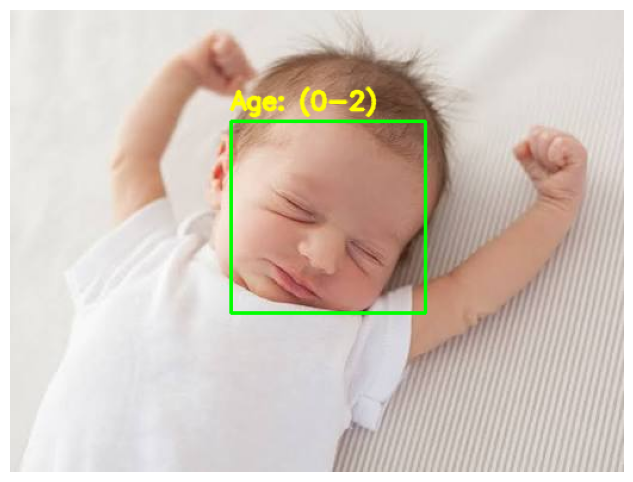

In [21]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Define Paths
model_dir = r"C:\Users\DELL\DL AGE_DETACTION\model_dir"

face_proto = os.path.join(model_dir, "opencv_face_detector.pbtxt")
face_model = os.path.join(model_dir, "opencv_face_detector_uint8.pb")
age_proto = os.path.join(model_dir, "age_deploy.prototxt")
age_model = os.path.join(model_dir, "age_net.caffemodel")

# 2. Load Deep Learning Networks
face_net = cv2.dnn.readNetFromTensorflow(face_model, face_proto)
age_net = cv2.dnn.readNetFromCaffe(age_proto, age_model)

# 3. Model Constants
# Predefined age buckets used by the Levi & Hassner Caffe model
age_list = [
    "(0-2)",
    "(4-6)",
    "(8-12)",
    "(15-20)",
    "(25-32)",
    "(38-43)",
    "(48-53)",
    "(60-100)",
]
MODEL_MEAN_VALUES = (78.4263377603, 87.7689143744, 114.895847746)


def detect_faces(net, frame, conf_threshold=0.7):
  frame_height = frame.shape[0]
  frame_width = frame.shape[1]
  blob = cv2.dnn.blobFromImage(
      frame, 1.0, (300, 300), [104, 117, 123], False, False
  )
  net.setInput(blob)
  detections = net.forward()
  face_boxes = []

  for i in range(detections.shape[2]):
    confidence = detections[0, 0, i, 2]
    if confidence > conf_threshold:
      x1 = int(detections[0, 0, i, 3] * frame_width)
      y1 = int(detections[0, 0, i, 4] * frame_height)
      x2 = int(detections[0, 0, i, 5] * frame_width)
      y2 = int(detections[0, 0, i, 6] * frame_height)
      face_boxes.append([x1, y1, x2, y2])

  return face_boxes


def predict_age(face, net):
  blob = cv2.dnn.blobFromImage(
      face, 1.0, (227, 227), MODEL_MEAN_VALUES, swapRB=False
  )
  net.setInput(blob)
  age_preds = net.forward()
  age = age_list[age_preds[0].argmax()]
  return age


def process_image(image_path):
  frame = cv2.imread(image_path)
  if frame is None:
    print(f"Error: Image not found at {image_path}")
    return

  output_frame = frame.copy()
  face_boxes = detect_faces(face_net, frame)

  for x1, y1, x2, y2 in face_boxes:
    # Add padding around face box
    padding = 20
    face = frame[
        max(0, y1 - padding) : min(y2 + padding, frame.shape[0] - 1),
        max(0, x1 - padding) : min(x2 + padding, frame.shape[1] - 1),
    ]

    if face.size == 0:
      continue

    age = predict_age(face, age_net)

    # Draw box & prediction on output frame
    cv2.rectangle(output_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        output_frame,
        f"Age: {age}",
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 255),
        2,
        cv2.LINE_AA,
    )

  # Display inside Jupyter Notebook using Matplotlib
  output_rgb = cv2.cvtColor(output_frame, cv2.COLOR_BGR2RGB)
  plt.figure(figsize=(8, 6))
  plt.imshow(output_rgb)
  plt.axis("off")
  plt.show()


# Example usage (corrected folder name to 'sample_photos')
image_path = r"C:\Users\DELL\DL AGE_DETACTION\sample_photos\baby.jpg"

print("Image exists:", os.path.exists(image_path))
process_image(image_path)

Image exists: True


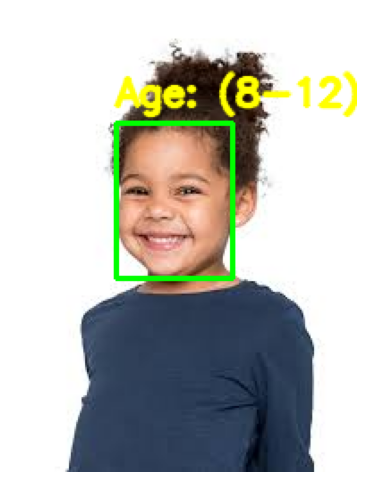

In [23]:
# Example usage (corrected folder name to 'sample_photos')
image_path = r"C:\Users\DELL\DL AGE_DETACTION\sample_photos\kid_girl.jpg"

print("Image exists:", os.path.exists(image_path))
process_image(image_path)

Image exists: True


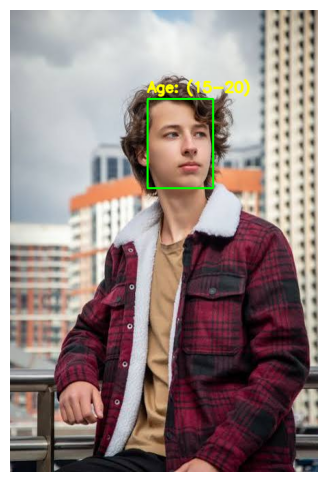

In [25]:
# Example usage (corrected folder name to 'sample_photos')
image_path = r"C:\Users\DELL\DL AGE_DETACTION\sample_photos\teenager.jpg"

print("Image exists:", os.path.exists(image_path))
process_image(image_path)

Image exists: True


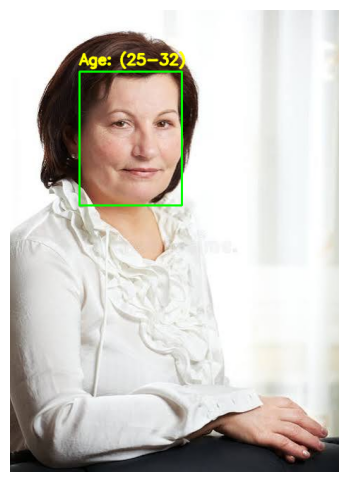

In [29]:
# Example usage (corrected folder name to 'sample_photos')
image_path = r"C:\Users\DELL\DL AGE_DETACTION\sample_photos\50_year_old women.jpg"

print("Image exists:", os.path.exists(image_path))
process_image(image_path)

In [ ]:
# Example usage (corrected folder name to 'sample_photos')
image_path = r"C:\Users\DELL\DL AGE_DETACTION\sample_photos\baby.jpg"

print("Image exists:", os.path.exists(image_path))
process_image(image_path)